# Gaussian beams (default 500,000): smiley → full microscope → detector

Move the **sample height** to defocus a **128 × 128** detector image. The second
slider changes display contrast only. An optional **Objective aberrations** panel
adds coma, twofold astigmatism, and spherical aberration. This uses the full `microscope.toml` at
**200 kV / 40,000×**, including magnetic image rotation. Lens currents and the
detector stay fixed after solving the nominal imaging condition.

Run all cells in the repository environment with the `inversion` notebook extras.
JAX's GPU backend gives interactive updates; CPU execution is supported but the
500,000-term coherent sum is much slower. The first render compiles; timings below
measure completed calculations and transfer to the notebook, excluding plotting.
The saved three-height preview and full-column ray overview are visible without starting a kernel.

The **Gaussians** selector offers **10,000, 50,000, 100,000, 250,000, 500,000,
and 1,000,000** beamlets. The first image at a new count compiles once; returning
to that count reuses its renderer and image cache. Both the focused reference and
the live image use the selected count, with the same microscope, specimen, and
illumination. Smaller counts are coarser numerical approximations. The saved
validation and previews below use the default 500,000.


In [9]:
from pathlib import Path
import os
import sys
from time import perf_counter
from types import SimpleNamespace

os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
repo = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/temgym_core").is_dir())
sys.path.insert(0, str(repo / "src"))
sys.path.insert(0, str(repo / "examples/microscope_models"))

import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm
import ipywidgets as widgets
from IPython.display import display
from importlib import reload
import smiley_defocus
SmileyDefocus = reload(smiley_defocus).SmileyDefocus
from temgym_core.run import column_matrix
from temgym_core.evaluate import evaluate_gaussians

%matplotlib inline
print("JAX:", jax.__version__, "Devices:", jax.devices())

JAX: 0.10.2 Devices: [CudaDevice(id=0)]


In [10]:
start = perf_counter()
demo = SmileyDefocus(lattice_shape=(500, 1000))
assert demo.num_beams == 500_000
incident = demo.incident_beamlets(jnp.asarray(0., dtype=jnp.float64))
assert incident.x.shape == (500_000,)
del incident
print(f"Setup: {perf_counter()-start:.2f} s; {demo.num_beams:,} Gaussian beamlets")
print(f"Detector: {demo.detector.shape}, {demo.detector.pixel_size[0]*1e6:g} µm pitch")
print(f"Specimen-equivalent pixel: {demo.detector.pixel_size[0]/demo.magnification*1e9:.3f} nm")
print("Renderer:", demo.method)
print("Column: source → CL1 → CL3 → deflectors → C_mini → Obj_prefield")
print("        → smiley → KrivanekLens + objective rotation → IL1 → IL2 → IL3 → PL1 → detector")
if demo.method == "scan":
    print("CPU fallback: expect slower updates at the full beam count.")

Setup: 7.46 s; 500,000 Gaussian beamlets
Detector: (128, 128), 55 µm pitch
Specimen-equivalent pixel: 1.375 nm
Renderer: spatial
Column: source → CL1 → CL3 → deflectors → C_mini → Obj_prefield
        → smiley → KrivanekLens + objective rotation → IL1 → IL2 → IL3 → PL1 → detector


The fixed condenser transports one coherent Gaussian analytically. At each
sample height, that transported wave is decomposed into **500 × 1,000 overlapping
Gaussian beamlets**, all of which interact with the smiley and propagate through
every downstream lens and drift. Re-decomposing at the specimen keeps the beamlets
narrow enough for the sample's local quadratic action expansion.

The illumination is an illustrative coherent source mode chosen for a 100 nm
amplitude radius at nominal sample height; it does not impose the TOML source size.
Apertures are open. The original smiley recipe is amplitude-normalized, bounded,
and smoothed over about 1.1 nm, with up to 0.8 rad of added phase. Its geometry and
striped signature are retained; this is a synthetic amplitude-and-phase specimen.

The intensity is **|sum of complex Gaussian fields|²**, point-sampled on the
128 × 128 detector. It is not a ray histogram or a pixel-integrated camera model.
The native spatial GPU renderer rebuilds support bins each frame and falls back
to its dense sum for broad beams. Precision is float64 with a 10⁻¹² envelope cutoff.

The **objective is a native `KrivanekLens`**. Its focal length is taken from the
microscope's `Obj_post` at the fixed operating current; the original objective's
magnetic rotation follows the Krivanek kick. All selected Gaussian beamlets pass
through this lens and then through IL1, IL2, IL3, and PL1 before field evaluation
on the detector. There is no Fourier filtering of the image.

The sliders set `KrivanekCoeffs.C12` (twofold astigmatism), `.C21` (axial coma),
and `.C30` (spherical aberration). Zero coefficients recover the original round
objective. Every new optical setting runs native propagation; recently visited
images are cached with the height and all three coefficients in the key.

`KrivanekLens` uses the native local quadratic Gaussian-action approximation.
Strong higher-order aberrations need a separate beamlet convergence study before
quantitative interpretation. The green diagram traces a stratified subset of actual Gaussian beam centres
through the same sample and aberrated objective as the image. Its shaded range
is not the individual Gaussian widths or the coherent intensity envelope.


In [11]:
# Warm compilation, then time fresh renders. The display also caches visited heights.
focus, cold_seconds, _ = demo.image(0.)
heights_um = (-10., 0., 10.)
preview = {}
warm_seconds = []
for height_um in heights_um:
    frame, seconds, _ = demo.image(height_um*1000., use_cache=False)
    preview[height_um] = frame
    demo.cache[height_um*1000.] = frame
    warm_seconds.append(seconds)
    print(f"Height {height_um:+5.1f} µm: {1000*seconds:7.1f} ms, including host copy")
print(f"First render, including compilation: {cold_seconds:.2f} s")

# Independent focus check: magnify and rotate the prescribed exit-wave intensity.
M = np.asarray(column_matrix(demo.downstream, source_z=demo.z_sample,
                             voltage=demo.model.voltage))
A = M[:2, :2]
np.testing.assert_allclose(np.linalg.svd(A, compute_uv=False), demo.magnification, rtol=1e-8)
np.testing.assert_allclose(M[:2, 2:4], 0., atol=1e-9)
object_coords = jnp.asarray(np.asarray(demo.detector.coords) @ np.linalg.inv(A).T)
object_grid = SimpleNamespace(coords=object_coords, shape=demo.detector.shape)
illumination_field = evaluate_gaussians(demo.nominal_illumination, object_grid, method="scan")
actions = demo.sample.evaluate_actions(object_coords)
reference = np.asarray(jnp.abs(illumination_field)**2 *
                       jnp.exp(2*actions[:, 1]).reshape(demo.detector.shape))
focus_error = np.linalg.norm(focus-reference) / np.linalg.norm(reference)
assert focus_error < 0.02, f"Focused transmission mismatch: {focus_error:.2%}"
print(f"Focused image vs direct transmission: {focus_error:.2%} relative L2 error")
for height_um in (-10., 10.):
    difference = np.linalg.norm(preview[height_um]-focus) / np.linalg.norm(focus)
    assert difference > 0.02
    shifted = np.asarray(column_matrix(demo.downstream,
        source_z=demo.z_sample+height_um*1e-6, voltage=demo.model.voltage))
    # Positive sample height is downstream: equivalent defocus B/A = -height.
    np.testing.assert_allclose(np.linalg.solve(shifted[:2, :2], shifted[:2, 2:4]),
                               -height_um*1e-6*np.eye(2), atol=1e-12)
    print(f"Height {height_um:+g} µm changes intensity by {difference:.1%} relative L2")
rotation_deg = np.degrees(np.arctan2(A[1, 0], A[0, 0]))
print(f"Image rotation: {rotation_deg:.1f}° (retained on the detector)")

Height -10.0 µm:   163.2 ms, including host copy
Height  +0.0 µm:    19.1 ms, including host copy
Height +10.0 µm:   163.8 ms, including host copy
First render, including compilation: 3.85 s
Focused image vs direct transmission: 0.50% relative L2 error
Height -10 µm changes intensity by 14.6% relative L2
Height +10 µm changes intensity by 9.2% relative L2
Image rotation: -0.0° (retained on the detector)


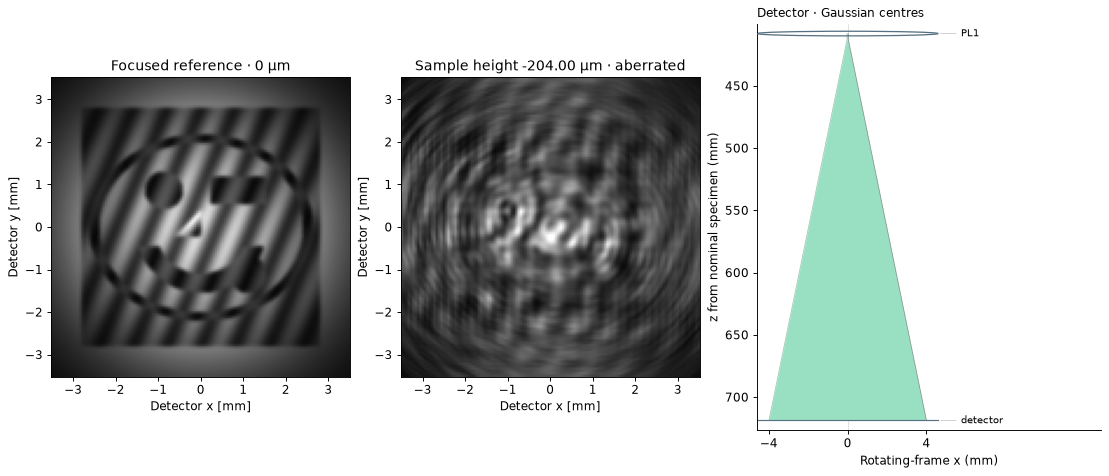

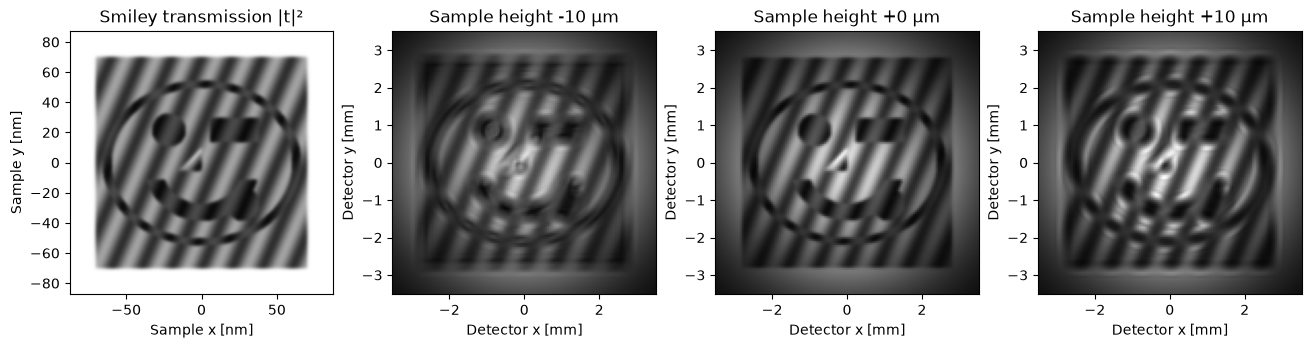

In [12]:
# Saved preview: common intensity scale, with no per-frame renormalization.
# Use pixel edges and the detector's row direction so +y stays upward.
xy = np.asarray(demo.detector.coords).reshape(128, 128, 2)
dy, dx = demo.detector.pixel_size
extent_mm = np.array([xy[..., 0].min()-dx/2, xy[..., 0].max()+dx/2,
                      xy[..., 1].min()-dy/2, xy[..., 1].max()+dy/2])*1e3
detector_origin = "upper" if xy[0, 0, 1] > xy[-1, 0, 1] else "lower"
half_sample_nm = demo.sample_map_width_m*1e9/2
vmax = max(float(frame.max()) for frame in preview.values())
fig, axes = plt.subplots(1, 4, figsize=(13, 3.7), constrained_layout=True)
axes[0].imshow(demo.sample_amplitude**2, origin="lower", cmap="gray", vmin=0, vmax=1,
               extent=(-half_sample_nm, half_sample_nm, -half_sample_nm, half_sample_nm))
axes[0].set(title="Smiley transmission |t|²", xlabel="Sample x [nm]", ylabel="Sample y [nm]")
for ax, height_um in zip(axes[1:], heights_um):
    ax.imshow(preview[height_um], origin=detector_origin, cmap="gray", vmin=0, vmax=vmax,
              extent=extent_mm)
    ax.set(title=f"Sample height {height_um:+g} µm", xlabel="Detector x [mm]", ylabel="Detector y [mm]")
plt.show()

### Native Krivanek objective examples

Each example changes one coefficient at nominal focus, on the same intensity
scale. The zero-coefficient check compares the native Krivanek objective with
the original electromagnetic objective using the same Gaussian illumination.

Astigmatism C₁₂ = 10 µm: 169.9 ms; image change 9.8%
Coma C₂₁ = 20 mm: 50.2 ms; image change 11.0%
Spherical C₃₀ = 50 m: 30.2 ms; image change 2.1%
Zero-coefficient KrivanekLens reproduces the original magnetic objective.


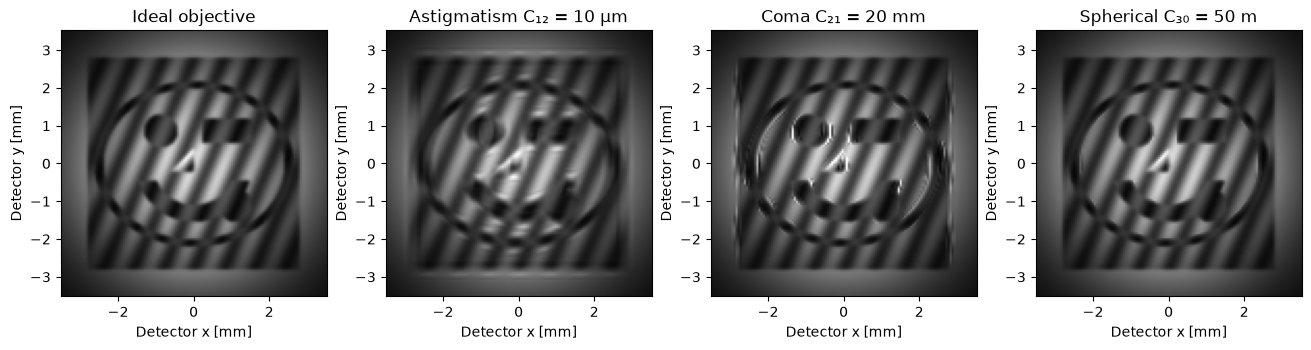

In [13]:
aberration_examples = [
    ("Astigmatism C₁₂ = 10 µm", dict(astigmatism_um=10.)),
    ("Coma C₂₁ = 20 mm", dict(coma_mm=20.)),
    ("Spherical C₃₀ = 50 m", dict(spherical_mm=50_000.)),
]
aberration_frames = []
for label, coefficients in aberration_examples:
    frame, seconds, _ = demo.image(0., **coefficients)
    change = np.linalg.norm(frame-focus)/np.linalg.norm(focus)
    assert change > 0.005, (label, change)
    aberration_frames.append(frame)
    print(f"{label}: {seconds*1000:.1f} ms; image change {change:.1%}")

from temgym_core.components import KrivanekLens
from temgym_core.run import run_to_end
assert isinstance(demo.objective_column()[0], KrivanekLens)
coefficients = demo.objective_column(10., 20., 50_000.)[0].coeffs
np.testing.assert_allclose([coefficients.C12, coefficients.C21, coefficients.C30],
                           [10e-6, 20e-3, 50.], rtol=1e-14)

@jax.jit
def original_ideal_image(height_nm):
    from dataclasses import replace
    sample = replace(demo.sample, z=demo.z_sample+height_nm*1e-9)
    output = run_to_end(demo.incident_beamlets(height_nm), (sample, *demo.downstream),
                        propagator=demo.propagator)
    field = evaluate_gaussians(output, demo.detector, method=demo.method, tile_beams=32)
    return jnp.abs(field*demo.magnification)**2

original_focus = np.asarray(original_ideal_image(jnp.asarray(0.)))
np.testing.assert_allclose(focus, original_focus, rtol=1e-7, atol=1e-9)
print("Zero-coefficient KrivanekLens reproduces the original magnetic objective.")
aber_fig, aber_axes = plt.subplots(1, 4, figsize=(13, 3.5), constrained_layout=True)
for ax, label, frame in zip(aber_axes, ["Ideal objective"]+[v[0] for v in aberration_examples],
                            [focus]+aberration_frames):
    ax.imshow(frame, origin=detector_origin, extent=extent_mm, cmap="gray", vmin=0, vmax=vmax)
    ax.set(title=label, xlabel="Detector x [mm]", ylabel="Detector y [mm]")
plt.show()

### Full microscope ray diagram

The same green envelope, lens symbols, and sectioned view used in
`microscope_calibration_pipeline.ipynb`, traced through this example's Gaussian propagation column. These four panels cover the whole column; transverse scales change
between sections so the condenser crossovers and detector expansion remain visible.

TypeError: _draw_ray_section() got an unexpected keyword argument 'scale_segments'

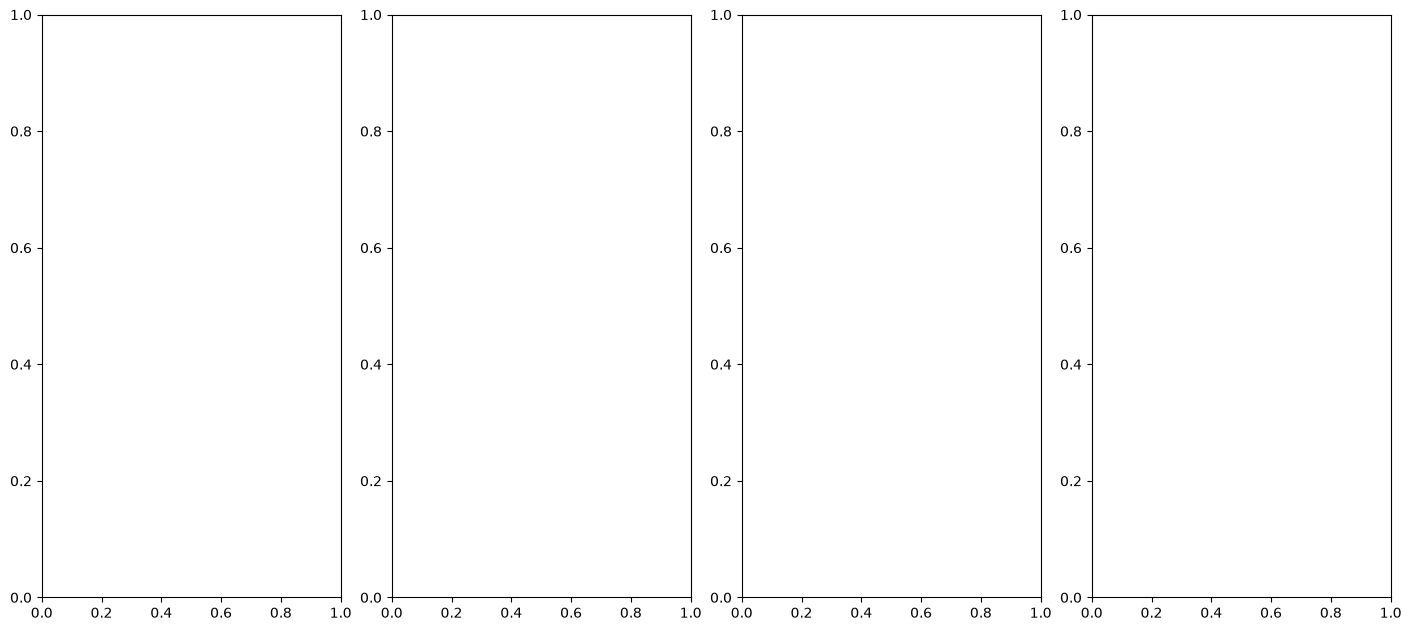

In [14]:
ray_fig, ray_axes = plt.subplots(1, 4, figsize=(14, 6.2), constrained_layout=True)
for section_index, ax in enumerate(ray_axes):
    demo.draw_rays(ax, height_nm=0., section=section_index)
plt.show()

### Move the sample and adjust the objective

Release the height slider to render. Positive height moves the sample downstream;
it does not refocus the lenses. Previously visited heights display from a small
image cache. The contrast slider reuses the current image immediately. **Reset**
returns to the nominal focus. The focused reference and **calibration ray diagram** stay beside the live image.
Each ray view keeps fixed axes based on the nominal focused beam.
Use **Ray view** to inspect the source, specimen, projector, or detector. The
**Specimen ±25 µm** view makes the height change easy to see.

The green diagram uses the calibration notebook's drawing style and a stratified
subset of the actual Gaussian beamlets. Their centres traverse the specimen,
`KrivanekLens`, objective rotation, and projector with the same propagation as
the image. Height, count, and aberration changes update the trace; contrast does
not retrace it. A dashed purple guide shows zero objective aberrations at the same
sample height. The green range covers sampled beam centres, not Gaussian widths
or interference fringes. Every detector image still uses the selected full count.

Numerical checks above verify the focus condition and visible defocus for this
smoothed sample. Increase detector sampling and refine the beamlet basis before
using this interactive preview for quantitative contrast measurements.

Open **Objective aberrations** and tick **Enable** to activate its three sliders.
All coefficients start at zero. Coma and astigmatism axes are fixed along specimen
x; changing the sign reverses coma or swaps the astigmatic axes. **Clear aberrations**
returns all three coefficients to zero, and unchecking Enable restores the ideal
objective while preserving your slider values.

Units are **µm for C₁₂**, **mm for C₂₁**, and **m for C₃₀**. The ranges are deliberately
large for visible changes in this 140 nm smiley overview: they are demonstration
settings, not typical objective-lens coefficients. Use smaller values in the
Python interface for a quantitative study at finer specimen sampling.


In [ ]:
%matplotlib widget
# Close only an earlier copy of this notebook's interactive panel when rerun.
if "live_fig" in globals():
    plt.close(live_fig)
if "controls" in globals():
    controls.close()

# A kernel may still hold the helper class from before fixed ray scales were added.
# Rerunning this cell repairs that stale instance without restarting the kernel.
from importlib import reload
from html import escape
import traceback
import smiley_defocus
if getattr(type(demo), "sampling_api_version", None) != 3:
    print("Refreshing the notebook helper and rebuilding the Gaussian model…")
    SmileyDefocus = reload(smiley_defocus).SmileyDefocus
    demo = SmileyDefocus(lattice_shape=demo.lattice_shape)
    focus, _, _ = demo.image(0.)

# Keep a separate compiled renderer and image cache for each selected basis.
# Reuse the same optics and specimen without repeating the imaging-condition solve.
base_demo = demo
sampling_options = {
    10_000: (100, 100), 50_000: (200, 250), 100_000: (250, 400),
    250_000: (500, 500), 500_000: (500, 1000), 1_000_000: (1000, 1000),
}
models_by_count = {base_demo.num_beams: base_demo}
gaussian_count = widgets.Dropdown(description="Gaussians", value=base_demo.num_beams,
    options=[(f"{count:,}", count) for count in sampling_options],
    style={"description_width": "100px"}, layout=widgets.Layout(width="280px"))

height = widgets.FloatSlider(value=0., min=-10., max=10., step=0.25,
    description="Height [µm]", continuous_update=False, readout_format="+.2f",
    style={"description_width": "100px"}, layout=widgets.Layout(width="520px"))
contrast = widgets.FloatSlider(value=1., min=0.4, max=1.8, step=0.05,
    description="Contrast γ", continuous_update=True,
    style={"description_width": "100px"}, layout=widgets.Layout(width="360px"))
reset = widgets.Button(description="Reset focus", icon="undo", layout=widgets.Layout(width="130px"))
ray_section = widgets.Dropdown(description="Ray view", value=2,
    options=[("Source → mini", 0), ("Mini → specimen", 1),
             ("Projector lenses", 2), ("Detector", 3), ("Specimen ±25 µm", 4)],
    style={"description_width": "70px"}, layout=widgets.Layout(width="300px"))
enable_aberrations = widgets.Checkbox(value=False, description="Enable objective aberrations")
aber_style = {"description_width": "165px"}
aber_layout = widgets.Layout(width="520px")
astigmatism = widgets.FloatSlider(value=0., min=-20., max=20., step=0.5,
    description="Astigmatism C₁₂ [µm]", continuous_update=False, disabled=True,
    style=aber_style, layout=aber_layout, readout_format="+.1f")
coma = widgets.FloatSlider(value=0., min=-50., max=50., step=1.,
    description="Coma C₂₁ [mm]", continuous_update=False, disabled=True,
    style=aber_style, layout=aber_layout, readout_format="+.1f")
spherical = widgets.FloatSlider(value=0., min=-100., max=100., step=1.,
    description="Spherical C₃₀ [m]", continuous_update=False, disabled=True,
    style=aber_style, layout=aber_layout, readout_format="+.1f")
clear_aberrations = widgets.Button(description="Clear aberrations", icon="undo")
aber_panel = widgets.Accordion(children=[widgets.VBox([
    enable_aberrations, astigmatism, coma, spherical, clear_aberrations,
    widgets.HTML("Large demonstration ranges for this 140 nm overview; axes fixed along specimen x."),
])], selected_index=None)
aber_panel.set_title(0, "Objective aberrations · KrivanekLens")
suspend_updates = False
status = widgets.HTML()
errors = widgets.Output()
with plt.ioff():
    live_fig, live_axes = plt.subplots(1, 3, figsize=(13.2, 5.6), constrained_layout=True,
        gridspec_kw={"width_ratios": [1, 1, 1.15]})
    reference_artist = live_axes[0].imshow(focus, origin=detector_origin, cmap="gray",
        extent=extent_mm, norm=PowerNorm(gamma=1., vmin=0., vmax=vmax))
    live_artist = live_axes[1].imshow(focus, origin=detector_origin, cmap="gray",
        extent=extent_mm, norm=PowerNorm(gamma=1., vmin=0., vmax=vmax))
    live_axes[0].set_title("Focused reference · 0 µm")
    live_axes[1].set_title("Sample height +0.00 µm")
    for ax in live_axes[:2]:
        ax.set(xlabel="Detector x [mm]", ylabel="Detector y [mm]")
    live_fig.canvas.toolbar_visible = False
    live_fig.canvas.header_visible = False
    live_fig.canvas.footer_visible = False

def current_aberrations():
    if not enable_aberrations.value:
        return {}
    return dict(astigmatism_um=astigmatism.value, coma_mm=coma.value,
                spherical_mm=spherical.value*1000.)

def update_height(change=None):
    if suspend_updates:
        return
    status.value = f"Rendering {demo.num_beams:,} Gaussian beams…"
    try:
        frame, seconds, cached = demo.image(height.value * 1000., **current_aberrations())
        live_artist.set_data(frame)
        objective_label = "aberrated" if any(current_aberrations().values()) else "ideal objective"
        live_axes[1].set_title(f"Sample height {height.value:+.2f} µm · {objective_label}")
        demo.draw_rays(live_axes[2], height.value*1000., ray_section.value, **current_aberrations())
        live_fig.canvas.draw_idle()
        timing = "cached frame" if cached else f"{seconds*1000:.0f} ms compute + transfer"
        status.value = f"<b>{demo.num_beams:,} beams · 128 × 128</b> &nbsp; {timing}"
    except Exception as exc:
        status.value = "Render failed; the previous image is still displayed."
        with errors:
            print(f"{type(exc).__name__}: {exc}")
        raise

def update_gaussian_count(change):
    global demo, focus
    count = change["new"]
    gaussian_count.disabled = True
    errors.outputs = ()
    status.value = f"Preparing {count:,} Gaussians (first use may compile)…"
    previous_demo, previous_focus = demo, focus
    previous_frame = np.array(live_artist.get_array(), copy=True)
    previous_titles = [ax.get_title() for ax in live_axes[:2]]
    try:
        candidate = models_by_count.get(count)
        if candidate is None:
            candidate = base_demo.with_lattice_shape(sampling_options[count])
        # Complete both renders before committing the selected model.
        new_focus, _, _ = candidate.image(0.)
        frame, seconds, cached = candidate.image(height.value*1000., **current_aberrations())
        demo, focus = candidate, new_focus
        reference_artist.set_data(focus)
        live_artist.set_data(frame)
        live_axes[0].set_title(f"Focused reference · {count:,} beams")
        objective_label = "aberrated" if any(current_aberrations().values()) else "ideal objective"
        live_axes[1].set_title(f"Sample height {height.value:+.2f} µm · {objective_label}")
        demo.draw_rays(live_axes[2], height.value*1000., ray_section.value, **current_aberrations())
        live_fig.canvas.draw_idle()
        models_by_count[count] = candidate
        timing = "cached frame" if cached else f"{seconds*1000:.0f} ms compute + transfer"
        status.value = f"<b>{count:,} beams · 128 × 128</b> &nbsp; {timing}"
    except Exception as exc:
        # Restore actual model state as well as the selector and visible images.
        detail = traceback.format_exc()
        demo, focus = previous_demo, previous_focus
        reference_artist.set_data(previous_focus)
        live_artist.set_data(previous_frame)
        for ax, title in zip(live_axes[:2], previous_titles):
            ax.set_title(title)
        gaussian_count.unobserve(update_gaussian_count, names="value")
        try:
            gaussian_count.value = previous_demo.num_beams
        finally:
            gaussian_count.observe(update_gaussian_count, names="value")
        status.value = (f"Count change failed: <b>{escape(type(exc).__name__)}</b>: "
                        f"{escape(str(exc))}. Retained {previous_demo.num_beams:,} beams.")
        # Direct append works in widget callbacks even when output capture does not.
        errors.append_stderr(detail)
        live_fig.canvas.draw_idle()
    finally:
        gaussian_count.disabled = False


def toggle_aberrations(change=None):
    for slider in (astigmatism, coma, spherical):
        slider.disabled = not enable_aberrations.value
    update_height()

def clear_objective(_):
    global suspend_updates
    suspend_updates = True
    try:
        astigmatism.value = coma.value = spherical.value = 0.
    finally:
        suspend_updates = False
    update_height()

def update_ray_view(change=None):
    demo.draw_rays(live_axes[2], height.value*1000., ray_section.value, **current_aberrations())
    live_fig.canvas.draw_idle()

def update_contrast(change=None):
    for artist in (reference_artist, live_artist):
        artist.set_norm(PowerNorm(gamma=contrast.value, vmin=0., vmax=vmax))
    live_fig.canvas.draw_idle()

gaussian_count.observe(update_gaussian_count, names="value")
height.observe(update_height, names="value")
for slider in (astigmatism, coma, spherical):
    slider.observe(update_height, names="value")
enable_aberrations.observe(toggle_aberrations, names="value")
clear_aberrations.on_click(clear_objective)
contrast.observe(update_contrast, names="value")
ray_section.observe(update_ray_view, names="value")
reset.on_click(lambda _: setattr(height, "value", 0.))
controls = widgets.VBox([gaussian_count, widgets.HBox([height, reset]), widgets.HBox([contrast, ray_section]), aber_panel, status,
                         live_fig.canvas, errors])
update_height()
display(controls)